In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
'''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
'''
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

"\nfor dirname, _, filenames in os.walk('/kaggle/input'):\n    for filename in filenames:\n        print(os.path.join(dirname, filename))\n"

In [4]:
df= pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")
score_cols = [f"scores_{i}" for i in range(23)]
df = df.drop(columns=score_cols)

In [6]:
df = df.sort_values(by="timestamp").reset_index(drop=True)


In [5]:
df.columns

Index(['timestamp', 'symbol', 'open', 'high', 'low', 'close', 'volume',
       'sma_10', 'sma_50', 'ema_20', 'rsi_14', 'macd', 'macd_signal',
       'macd_hist', 'volatility_20', 'target_up_next', 'day', 'hour',
       'sum_of_scores', 'avg_of_scores', 'normalized_avg', 'max_of_scores',
       'min_of_scores', 'normalized_min', 'normalized_max',
       'avg_score_of_normalized_min', 'avg_score_of_normalized_max',
       'avg_score_of_normalized_avg'],
      dtype='object')

### Trying aggregate scores combinations

# LSTM

## Other financial indicators

###### based on github

In [8]:
df1= df[['close','sma_10', 'sma_50', 'ema_20', 'rsi_14', 'macd', 'macd_signal',
       'macd_hist', 'volatility_20']]
print(df1.isna().sum())          # show which features have NaNs
df1 = df1.dropna()                # or: df = df.fillna(method="ffill").fillna(method="bfill")


close            0
sma_10           0
sma_50           0
ema_20           0
rsi_14           0
macd             0
macd_signal      0
macd_hist        0
volatility_20    2
dtype: int64


<Axes: >

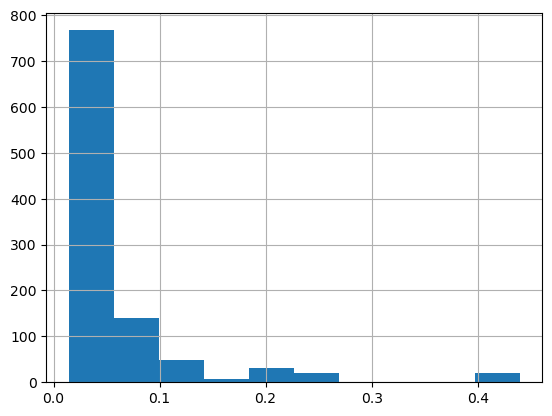

In [10]:
df1["volatility_20"].hist()

In [11]:
df['volatility_20'] = df['volatility_20'].fillna(method="ffill").fillna(method="bfill")


C:\Users\dmonz\AppData\Local\Temp\ipykernel_21336\3521975697.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df['volatility_20'] = df['volatility_20'].fillna(method="ffill").fillna(method="bfill")


<Axes: >

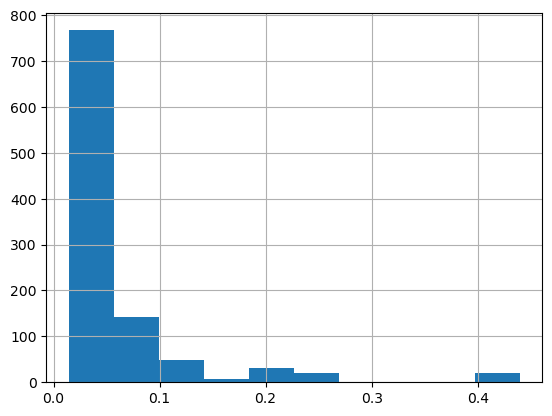

In [12]:
df["volatility_20"].hist()

Epoch 1/1000


C:\Users\dmonz\Anaconda3\envs\cs474hw1\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - loss: 0.2694
Epoch 2/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.1307
Epoch 3/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0502
Epoch 4/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0244 
Epoch 5/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0346
Epoch 6/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0404
Epoch 7/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0319
Epoch 8/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.0224
Epoch 9/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0181
Epoch 10/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0188
Epoch 11/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 0.0174
Epoch 12/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0191
Epoch 13/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 0.0190
Epoch 14/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.0137 
Epoch 15/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0139
Epoch 16/1000
3

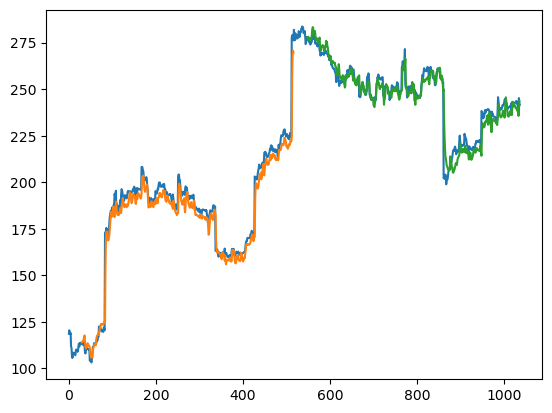

In [16]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1, target_col=0):
    dataX, dataY = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), :]          # full feature window
        dataX.append(a)
        dataY.append(dataset[i + look_back, target_col])
    return np.array(dataX), np.array(dataY)

# fix random seed for reproducibility
np.random.seed(5)


# take close price column[5]
#all_y = df["close"].values
dataset = df[['close','sma_10', 'sma_50', 'ema_20', 'rsi_14', 'macd', 'macd_signal',
       'macd_hist', 'volatility_20']].values
#dataset=all_y.reshape(-1, 1)
target_col = 0 # target label is Close



# normalize ALL features
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

# split into train and test sets, 50% test data
train_size = int(len(dataset) * 0.5)
train, test = dataset[0:train_size, :], dataset[train_size:, :]

# create supervised dataset
look_back = 30
trainX, trainY = create_dataset(train, look_back, target_col)
testX, testY = create_dataset(test, look_back, target_col)

# reshape input to be [samples, time steps, features]
n_features = dataset.shape[1]
trainX = trainX.reshape(trainX.shape[0], look_back, n_features)
testX = testX.reshape(testX.shape[0], look_back, n_features)

# LSTM model
model = Sequential()
model.add(LSTM(25, input_shape=(look_back, n_features)))
model.add(Dropout(0.1))
model.add(Dense(1))
model.compile(loss='mse', optimizer='adam')
model.fit(trainX, trainY, epochs=1000, batch_size=240, verbose=1)

# predictions
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)

# invert prediction scaling (only target)
trainPredict = scaler.inverse_transform(
    np.repeat(trainPredict, n_features, axis=1)
)[:,target_col]

trainY_inv = scaler.inverse_transform(
    np.repeat(trainY.reshape(-1,1), n_features, axis=1)
)[:,target_col]

testPredict = scaler.inverse_transform(
    np.repeat(testPredict, n_features, axis=1)
)[:,target_col]

testY_inv = scaler.inverse_transform(
    np.repeat(testY.reshape(-1,1), n_features, axis=1)
)[:,target_col]

# RMSE
trainScore = math.sqrt(mean_squared_error(trainY_inv, trainPredict))
testScore = math.sqrt(mean_squared_error(testY_inv, testPredict))
print('Train Score: %.2f RMSE' % trainScore)
print('Test Score: %.2f RMSE' % testScore)

# prepare plotting arrays
dataset_target = scaler.inverse_transform(dataset)[:, target_col]

trainPredictPlot = np.empty_like(dataset_target)
trainPredictPlot[:] = np.nan
trainPredictPlot[look_back:len(trainPredict)+look_back] = trainPredict

testPredictPlot = np.empty_like(dataset_target)
testPredictPlot[:] = np.nan
testPredictPlot[len(trainPredict)+(look_back*2)+1 : len(dataset_target)-1] = testPredict

# plot
plt.plot(dataset_target)
plt.plot(trainPredictPlot)
plt.plot(testPredictPlot)
plt.show()

# export results
testPrices = dataset_target[len(dataset_target)-len(testPredict):]
df_out = pd.DataFrame({
    "prediction": np.around(testPredict, 2),
    "test_price": np.around(testPrices, 2)
})
df_out.to_csv("lstm_result_model2.csv", sep=';', index=None)